# IF · K-means · LOF 피처 중요도

학습된 최신 모델과 경보 기준을 그대로 둔 **사후 분석**이다. 장기간 모델은 포함하지 않는다.

**방법:** 정상 기준으로 변환된 신호를 하나씩 정상 수준(0)으로 바꾸고, 최종 판정의 F1이 얼마나 감소하는지 측정한다. 양수가 크면 이 평가에서 의존도가 높았고, 음수면 해당 신호를 제거했을 때 F1이 개선되었다. 다시 학습한 성능이 아니며, 중요도 합이 100%인 비율도 아니다.

In [1]:
from pathlib import Path
import json,pandas as pd
from IPython.display import display,Image,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'reports/shared_model_v7/feature_importance/importance.json').exists())
OUT=ROOT/'reports/shared_model_v7/feature_importance'
r=json.loads((OUT/'importance.json').read_text(encoding='utf-8'))
name={'if':'Isolation Forest','kmeans':'MiniBatch K-means','lof':'LOF'}
display(pd.DataFrame(r['sample']))
display(pd.DataFrame(r['baseline']).assign(모델=lambda d:d.algorithm.map(name))[['모델','task','accuracy','precision','recall','f1','fpr']].round(4))

,task,이상 사례,짝 정상 사례,분 판정,이상 분,정상 분
0,individual_delay,200,200,2400,206,2194
1,group_delay,200,200,14552,2205,12347
2,time_burst,200,200,15998,1663,14335
3,input_stop,200,200,20104,3189,16915
4,gradual_degradation,200,200,24086,5990,18096


,모델,task,accuracy,precision,recall,f1,fpr
0,Isolation Forest,individual_delay,0.9758,1.0000,0.7184,0.8362,0.0000
1,Isolation Forest,group_delay,0.9718,0.8903,0.9279,0.9087,0.0204
2,Isolation Forest,time_burst,0.9447,0.8430,0.5749,0.6836,0.0124
3,Isolation Forest,input_stop,0.9574,0.9509,0.7714,0.8518,0.0075
4,Isolation Forest,gradual_degradation,0.8991,0.8934,0.6746,0.7688,0.0266
5,MiniBatch K-means,individual_delay,0.9692,1.0000,0.6408,0.7811,0.0000
6,MiniBatch K-means,group_delay,0.9806,0.9219,0.9524,0.9369,0.0144
7,MiniBatch K-means,time_burst,0.9469,0.8769,0.5695,0.6905,0.0093
8,MiniBatch K-means,input_stop,0.9521,0.9588,0.7297,0.8287,0.0059
9,MiniBatch K-means,gradual_degradation,0.8883,0.9388,0.5893,0.7241,0.0127


## 1. 먼저 피처 묶음으로 확인

현재 지연·지연 지속·증가 추세·요청 증가·입력 공백의 다섯 묶음이다. 관련 피처를 함께 정상 수준으로 바꾸며, 현재 지연 묶음에는 조건부 정상 이웃 통계, 요청 증가 묶음에는 PMF 상태 통계도 포함한다.

IF는 최종 학습 코어 입력이 1개 종합 신호이므로 내부 입력 중요도를 뽑으면 해석이 어렵다. 여기서는 **압축 전 신호 → 학습 모델 → 추가 정상 통계 → 경보 보정**을 포함한 전체 파이프라인을 설명한다.

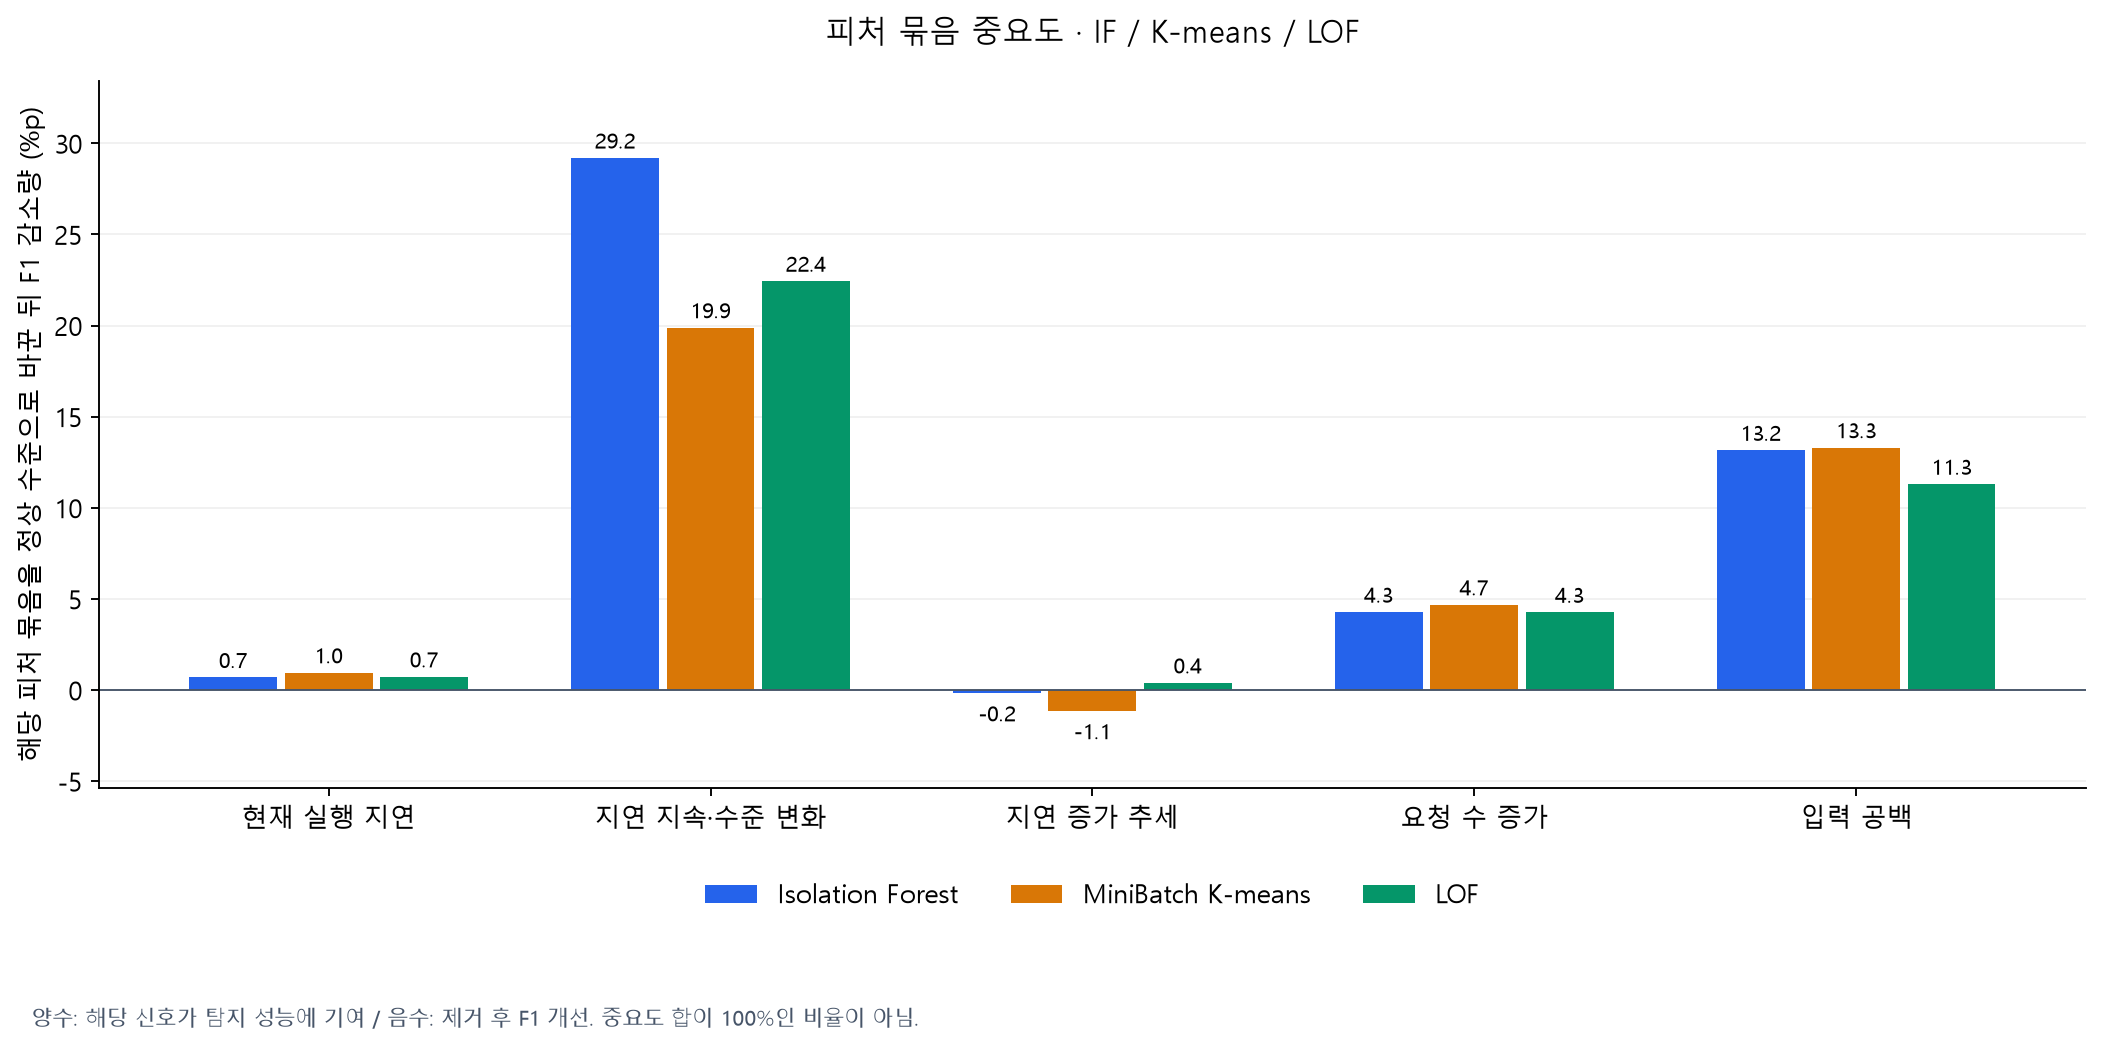

,algorithm,label,f1_drop_pp,recall_drop_pp,f1_drop_ci95_pp
0,if,현재 실행 지연,0.692,1.132,"[0.6009604884730385, 0.772730299424981]"
1,if,지연 지속·수준 변화,29.197,36.746,"[26.870418204578908, 31.344579960833663]"
2,if,지연 증가 추세,-0.160,0.008,"[-0.2437929297804889, -0.07591853655220891]"
3,if,요청 수 증가,4.279,7.123,"[3.9576229977191986, 4.600511350902656]"
4,if,입력 공백,13.158,18.630,"[11.969624223273268, 14.311891701538007]"
5,kmeans,현재 실행 지연,0.951,1.502,"[0.7586391013315191, 1.1814128569331466]"
6,kmeans,지연 지속·수준 변화,19.884,25.345,"[18.09435356471039, 21.606572423587853]"
7,kmeans,지연 증가 추세,-1.140,-2.573,"[-1.4487331167917685, -0.8102282248965282]"
8,kmeans,요청 수 증가,4.680,7.153,"[4.325443960372559, 5.035554952778071]"
9,kmeans,입력 공백,13.304,17.468,"[12.03316476548674, 14.506772422263007]"


In [2]:
display(Image(filename=str(OUT/'group_importance.png')))
g=pd.DataFrame([x for x in r['pooled_importance'] if x['kind']=='group'])
display(g[['algorithm','label','f1_drop_pp','recall_drop_pp','f1_drop_ci95_pp']].round(3))

### 이번 표본의 핵심 결과

- **Isolation Forest**: 최근 상단 이탈의 지속 신호 +11.70%p; 연속 0건의 정상 기준 드문 정도 +4.78%p; 추가 통계: 요청 수 PMF 상태 신호 +3.73%p
- **MiniBatch K-means**: 최근 상단 이탈의 지속 신호 +13.37%p; 연속 0건의 정상 기준 드문 정도 +11.87%p; 추가 통계: 요청 수 PMF 상태 신호 +3.80%p
- **LOF**: 최근 상단 이탈의 지속 신호 +13.32%p; 연속 0건의 정상 기준 드문 정도 +10.28%p; 추가 통계: 요청 수 PMF 상태 신호 +3.60%p

전체 수치는 분 판정을 합산하므로 시나리오별 길이와 정상·이상 비율의 영향을 받는다. 예를 들어 개별 지연의 현재 실행 신호는 전체 합산 기여가 작더라도 해당 시나리오에서 크게 작동할 수 있다.

점진적 악화에서도 단순 증가 기울기만 아니라 지연의 지속·수준 변화가 중요할 수 있다. 따라서 “LOF는 기울기를 학습해서 강하다”처럼 알고리즘의 원리로 단정하지 않는다.

## 2. 개별 피처는 무엇을 의미하나

15개 원천 수치 신호와 2개 추가 통계 신호를 각각 바꾼 결과다. 상관된 다른 피처가 정보를 대신할 수 있으므로, 개별 중요도가 작아도 전체 묶음 중요도는 클 수 있다. **Adapter·Process ID는 정상 통계와 경보 기준을 고르는 키이므로 숫자 피처와 같은 방법으로 섞지 않았다.**

### Isolation Forest

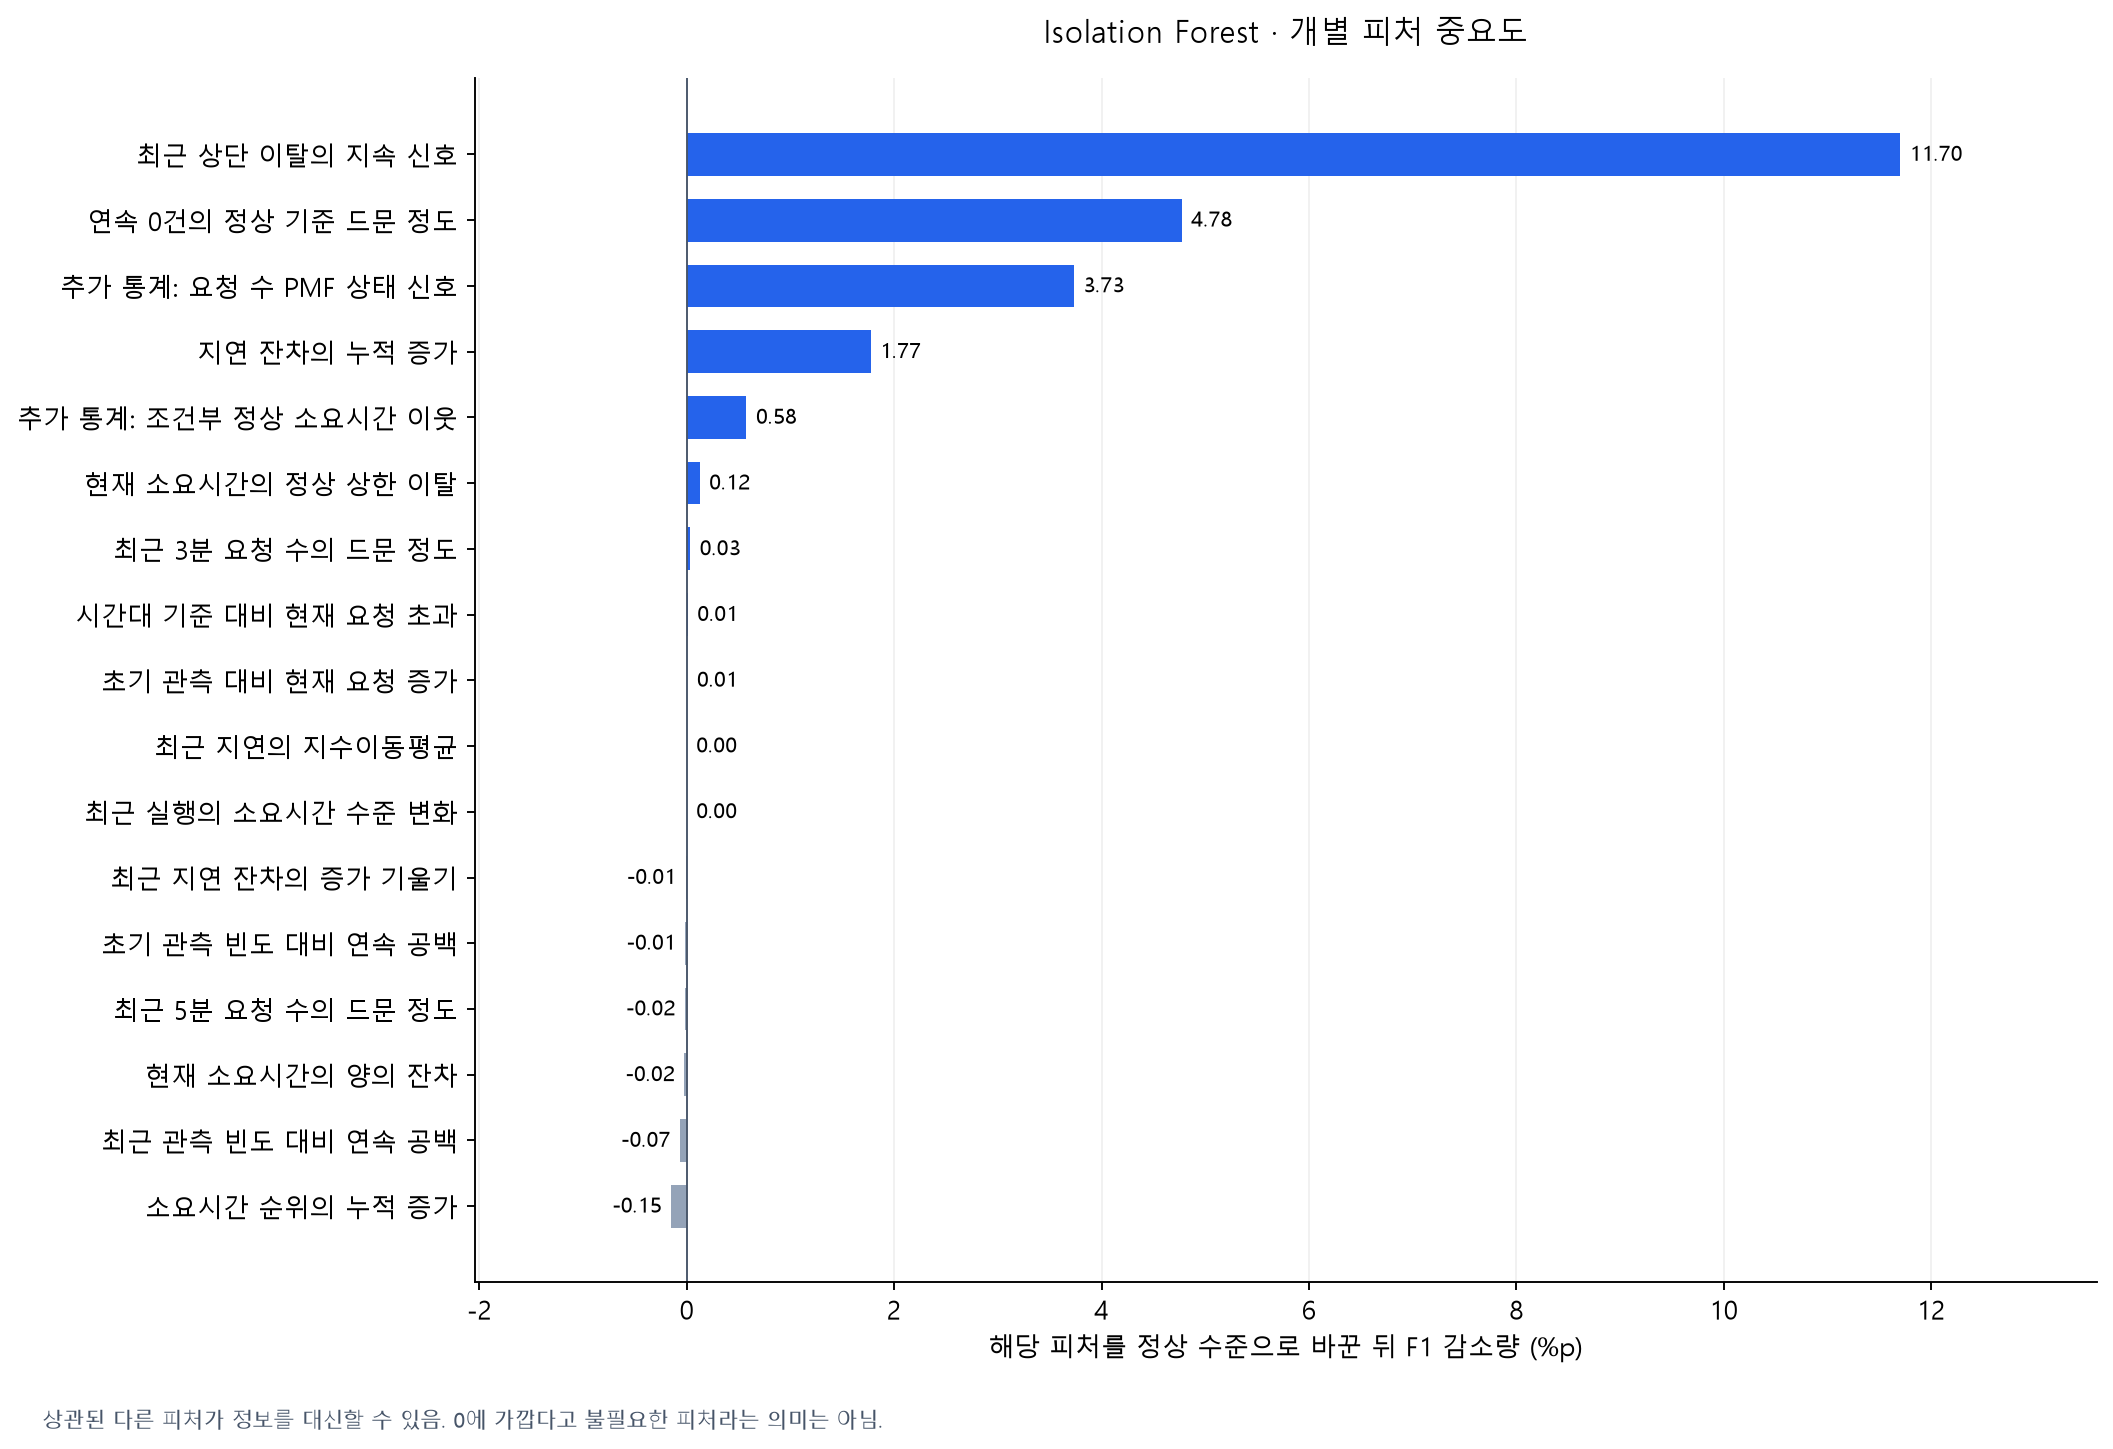

,name,label,f1_drop_pp,recall_drop_pp
4,rank_upper_memory,최근 상단 이탈의 지속 신호,11.700,17.196
13,traffic_zero_logprob,연속 0건의 정상 기준 드문 정도,4.775,7.327
16,aux_burst,추가 통계: 요청 수 PMF 상태 신호,3.733,6.142
3,seq_delay_cusum,지연 잔차의 누적 증가,1.773,3.380
15,aux_point,추가 통계: 조건부 정상 소요시간 이웃,0.576,0.958
0,current_source_upper,현재 소요시간의 정상 상한 이탈,0.125,0.189
8,traffic_tail_3m,최근 3분 요청 수의 드문 정도,0.033,0.075
11,current_arrival_excess,시간대 기준 대비 현재 요청 초과,0.010,0.015
10,current_prefix_burst,초기 관측 대비 현재 요청 증가,0.007,0.000
2,seq_last_shift,최근 실행의 소요시간 수준 변화,0.000,0.000


In [3]:
display(Image(filename=str(OUT/'if_feature_importance.png')))
f=pd.DataFrame([x for x in r['pooled_importance'] if x['kind']=='feature' and x['algorithm']=='if'])
display(f[['name','label','f1_drop_pp','recall_drop_pp']].sort_values('f1_drop_pp',ascending=False).round(3))

### MiniBatch K-means

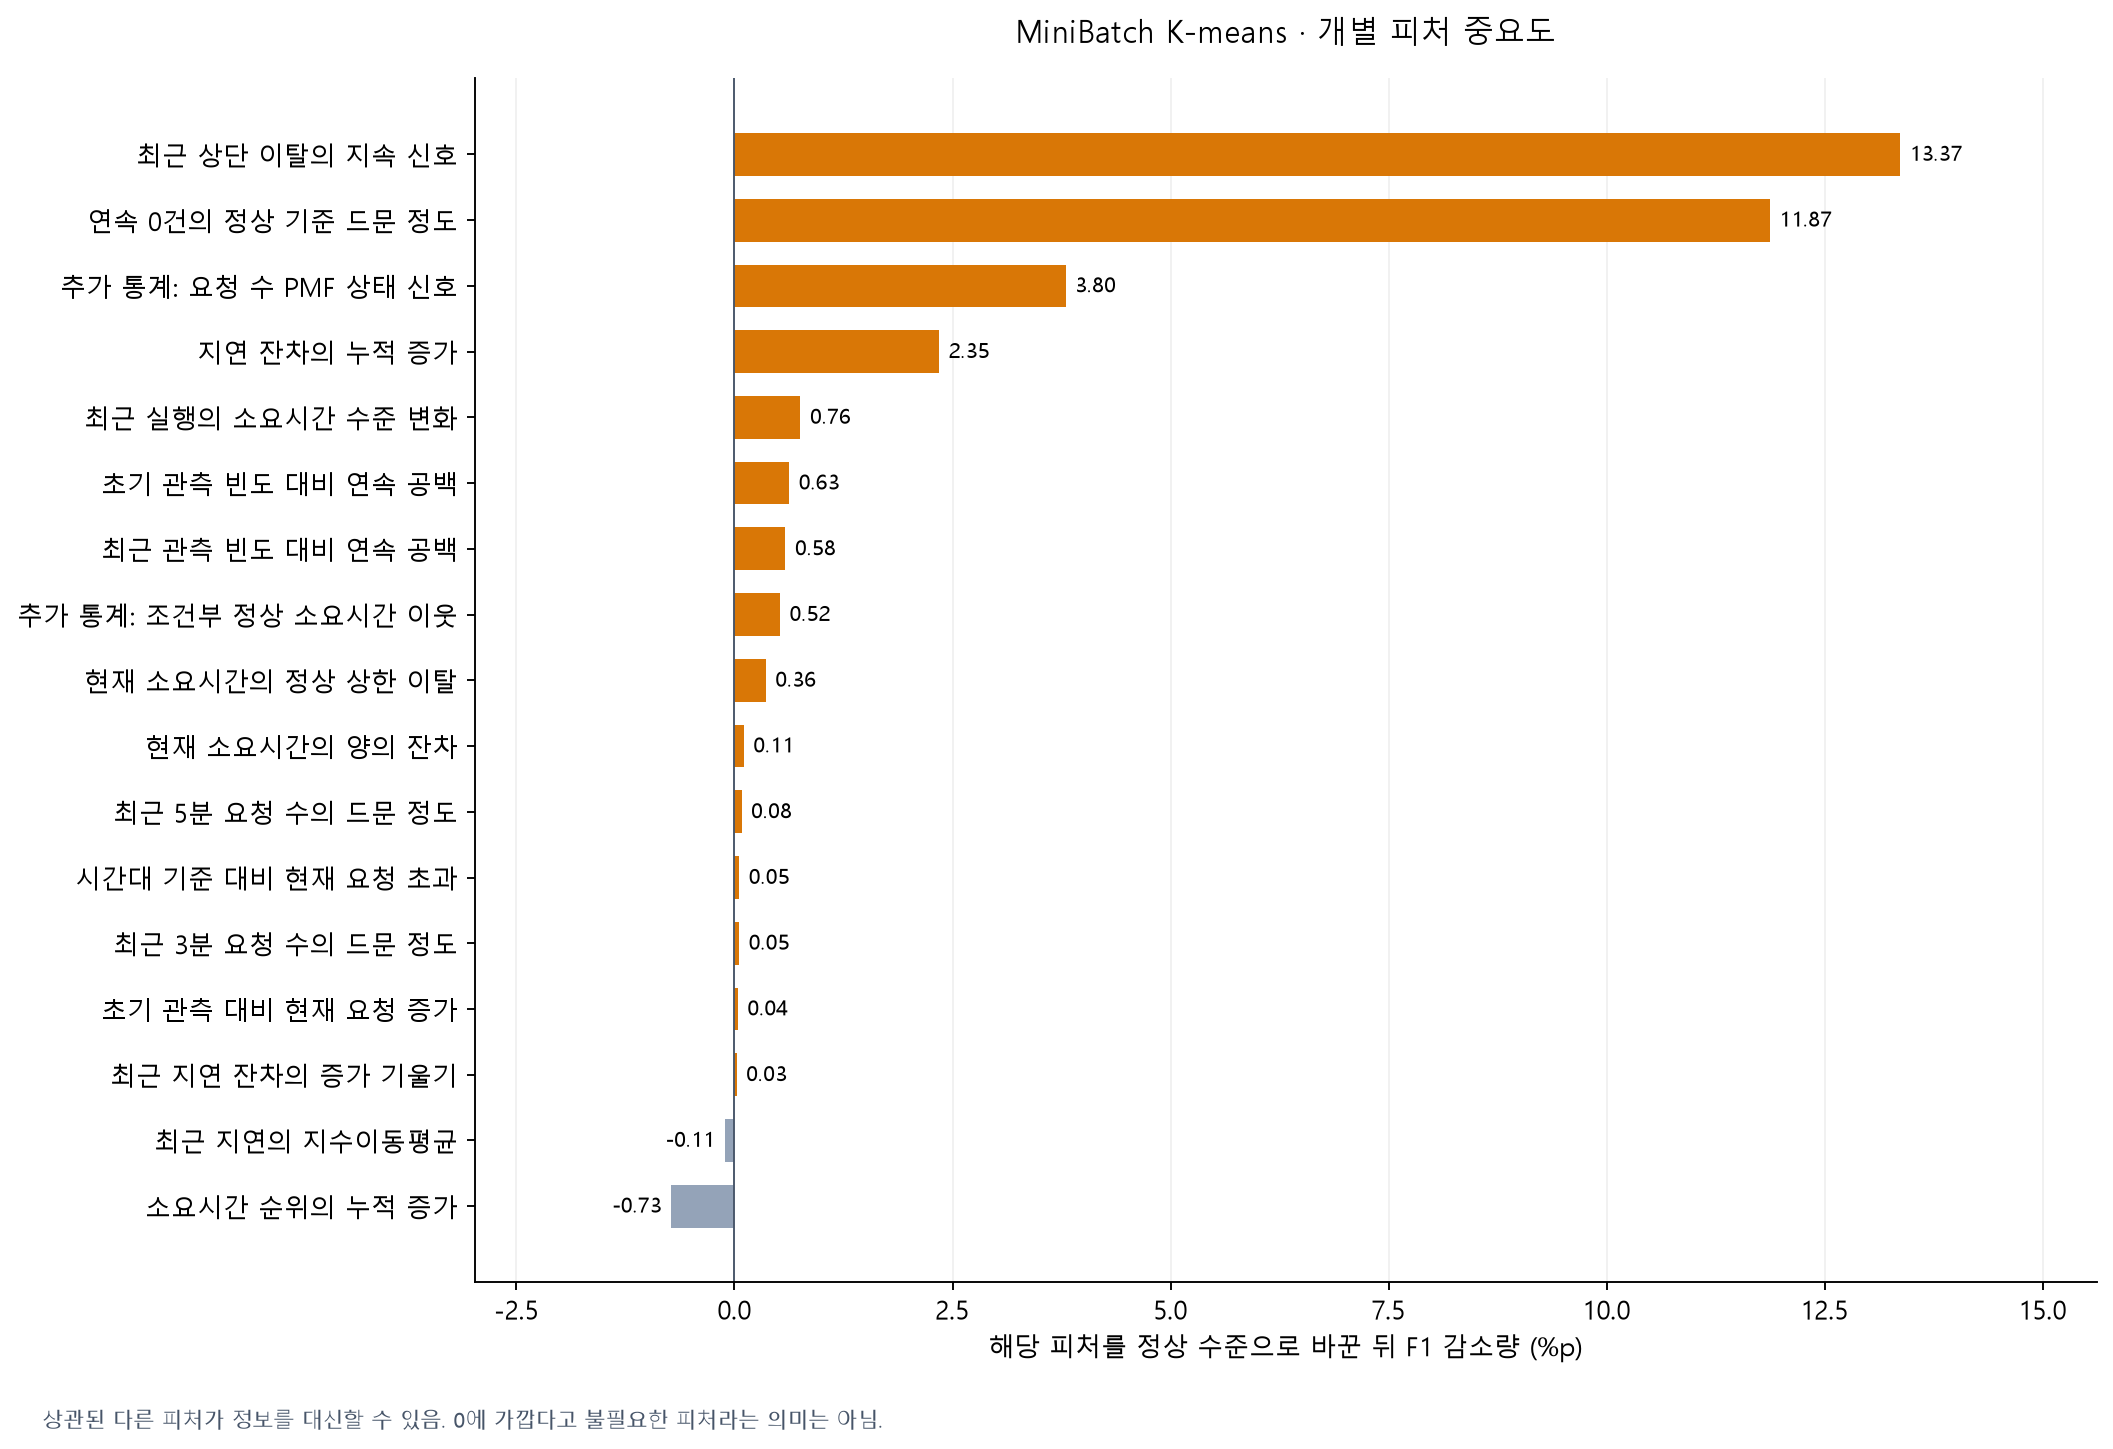

,name,label,f1_drop_pp,recall_drop_pp
4,rank_upper_memory,최근 상단 이탈의 지속 신호,13.366,17.815
13,traffic_zero_logprob,연속 0건의 정상 기준 드문 정도,11.871,15.770
16,aux_burst,추가 통계: 요청 수 PMF 상태 신호,3.797,5.795
3,seq_delay_cusum,지연 잔차의 누적 증가,2.347,4.127
2,seq_last_shift,최근 실행의 소요시간 수준 변화,0.757,1.320
12,gap_expected_prefix,초기 관측 빈도 대비 연속 공백,0.628,0.988
14,gap_expected_recent,최근 관측 빈도 대비 연속 공백,0.585,0.913
15,aux_point,추가 통계: 조건부 정상 소요시간 이웃,0.522,0.747
0,current_source_upper,현재 소요시간의 정상 상한 이탈,0.359,0.521
1,current_source_delay,현재 소요시간의 양의 잔차,0.107,0.309


In [4]:
display(Image(filename=str(OUT/'kmeans_feature_importance.png')))
f=pd.DataFrame([x for x in r['pooled_importance'] if x['kind']=='feature' and x['algorithm']=='kmeans'])
display(f[['name','label','f1_drop_pp','recall_drop_pp']].sort_values('f1_drop_pp',ascending=False).round(3))

### LOF

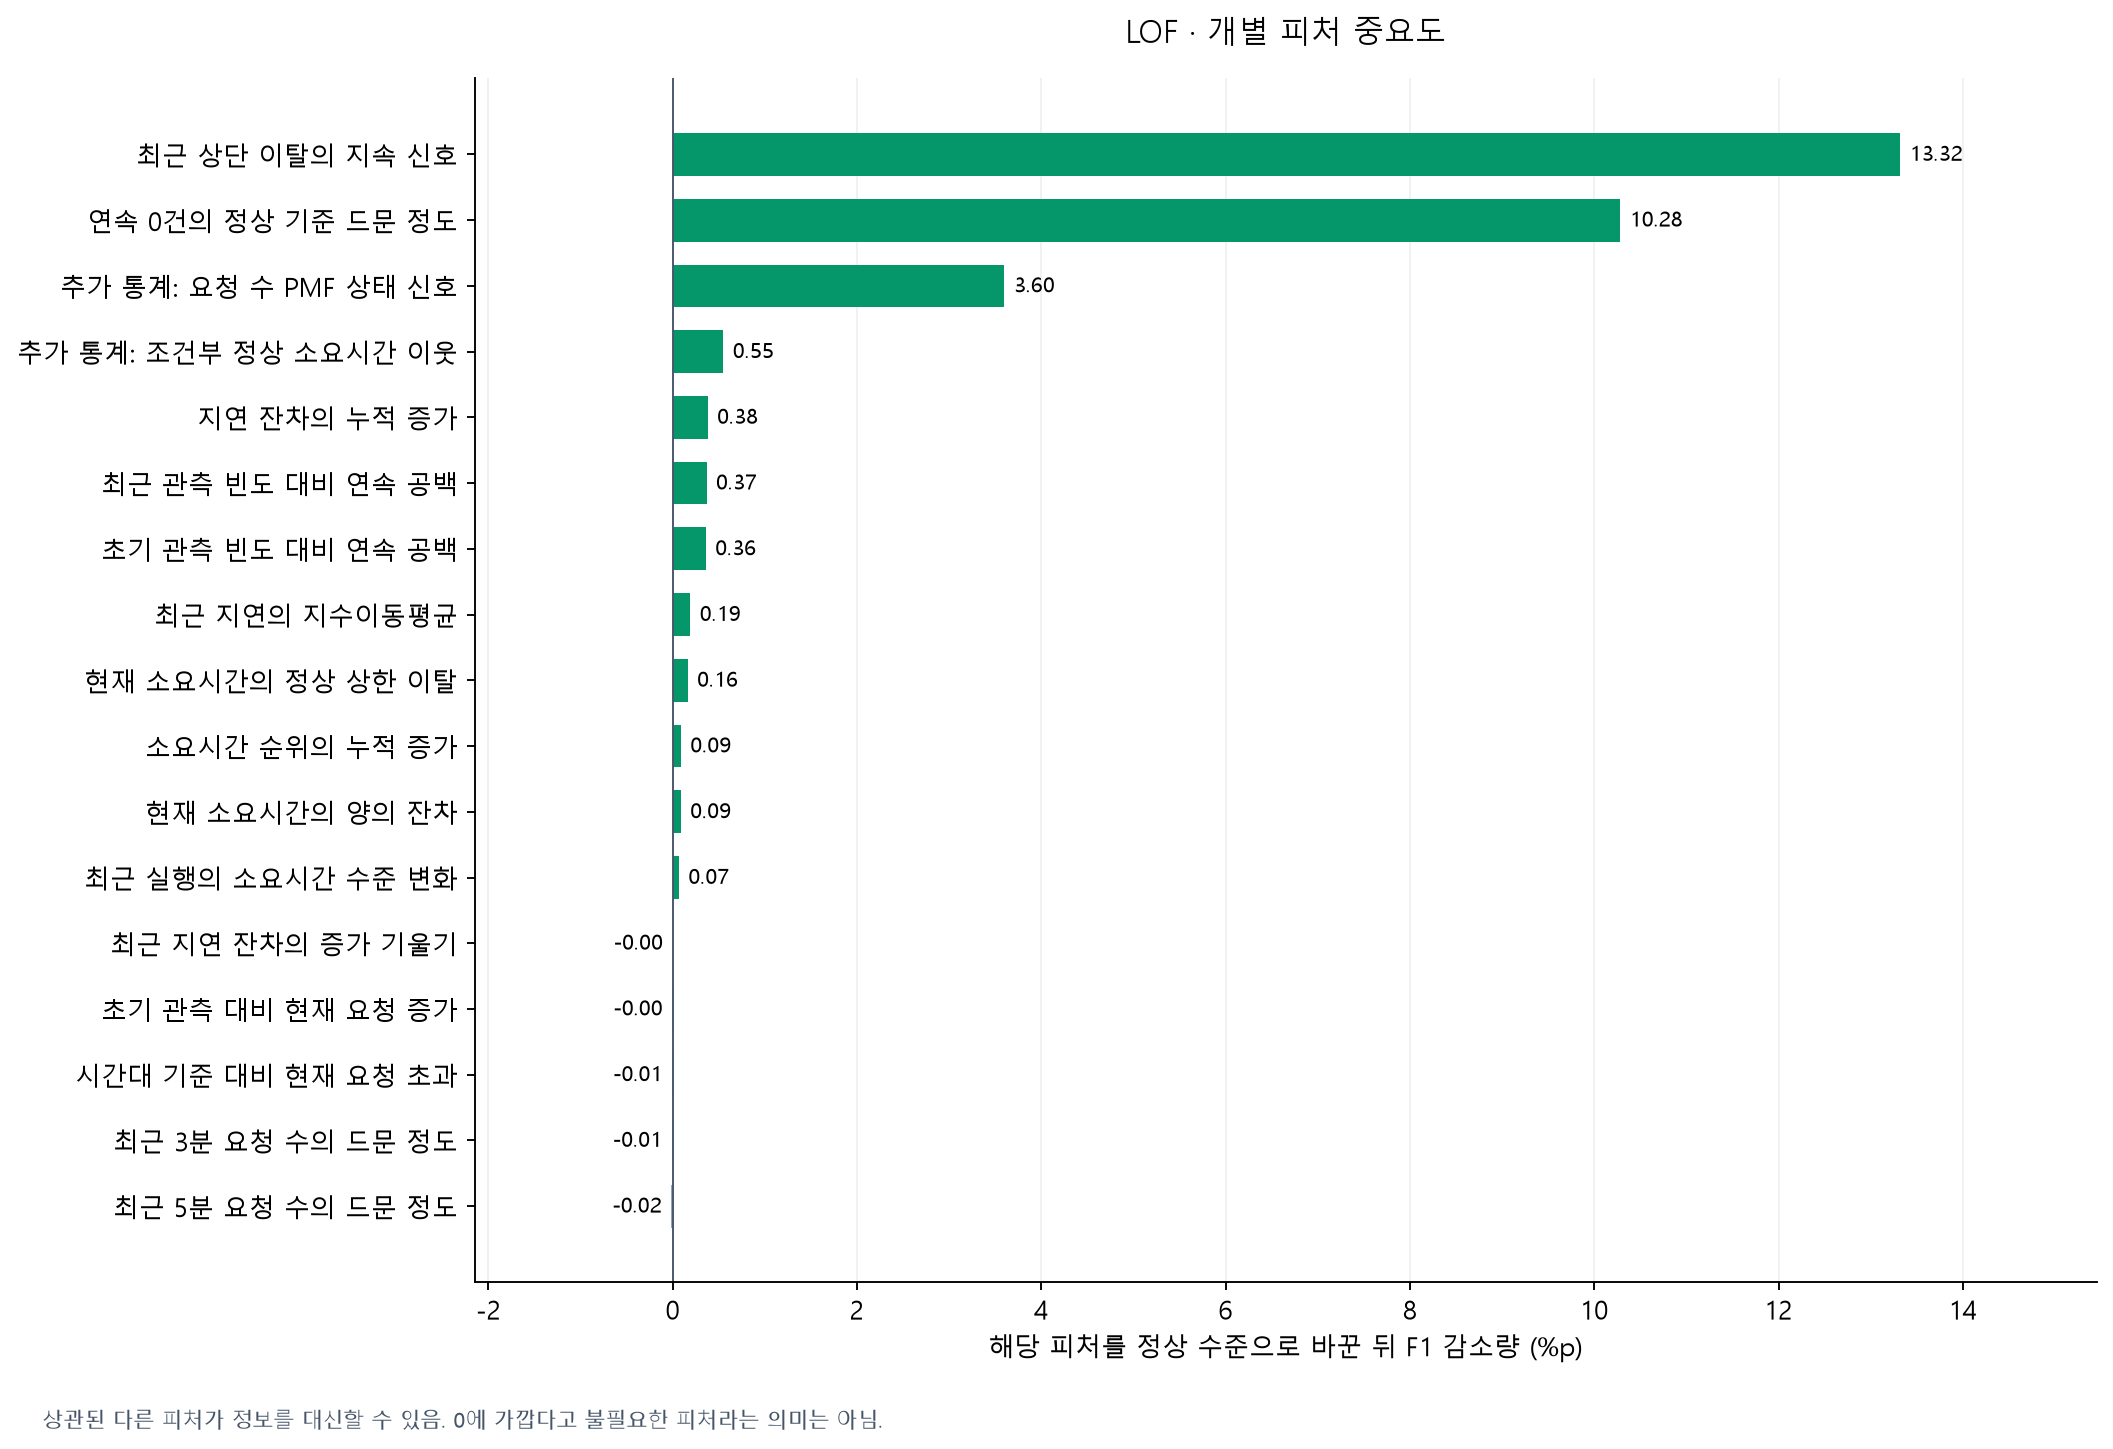

,name,label,f1_drop_pp,recall_drop_pp
4,rank_upper_memory,최근 상단 이탈의 지속 신호,13.320,19.837
13,traffic_zero_logprob,연속 0건의 정상 기준 드문 정도,10.282,14.495
16,aux_burst,추가 통계: 요청 수 PMF 상태 신호,3.600,5.765
15,aux_point,추가 통계: 조건부 정상 소요시간 이웃,0.549,0.830
3,seq_delay_cusum,지연 잔차의 누적 증가,0.380,1.705
14,gap_expected_recent,최근 관측 빈도 대비 연속 공백,0.367,0.619
12,gap_expected_prefix,초기 관측 빈도 대비 연속 공백,0.359,0.611
7,seq_delay_ewma,최근 지연의 지수이동평균,0.191,-0.981
0,current_source_upper,현재 소요시간의 정상 상한 이탈,0.162,0.158
5,rank_duration_cusum,소요시간 순위의 누적 증가,0.088,-0.377


In [5]:
display(Image(filename=str(OUT/'lof_feature_importance.png')))
f=pd.DataFrame([x for x in r['pooled_importance'] if x['kind']=='feature' and x['algorithm']=='lof'])
display(f[['name','label','f1_drop_pp','recall_drop_pp']].sort_values('f1_drop_pp',ascending=False).round(3))

## 3. 시나리오별로 보면

아래 그래프는 모델이 해당 시나리오에서 **어느 정보를 활용했는지** 보여준다. 특정 모델이 다른 모델보다 성능이 좋은지 비교하는 그래프는 아니다. 그 비교는 기존 성능표로 확인해야 한다.

### 개별 지연

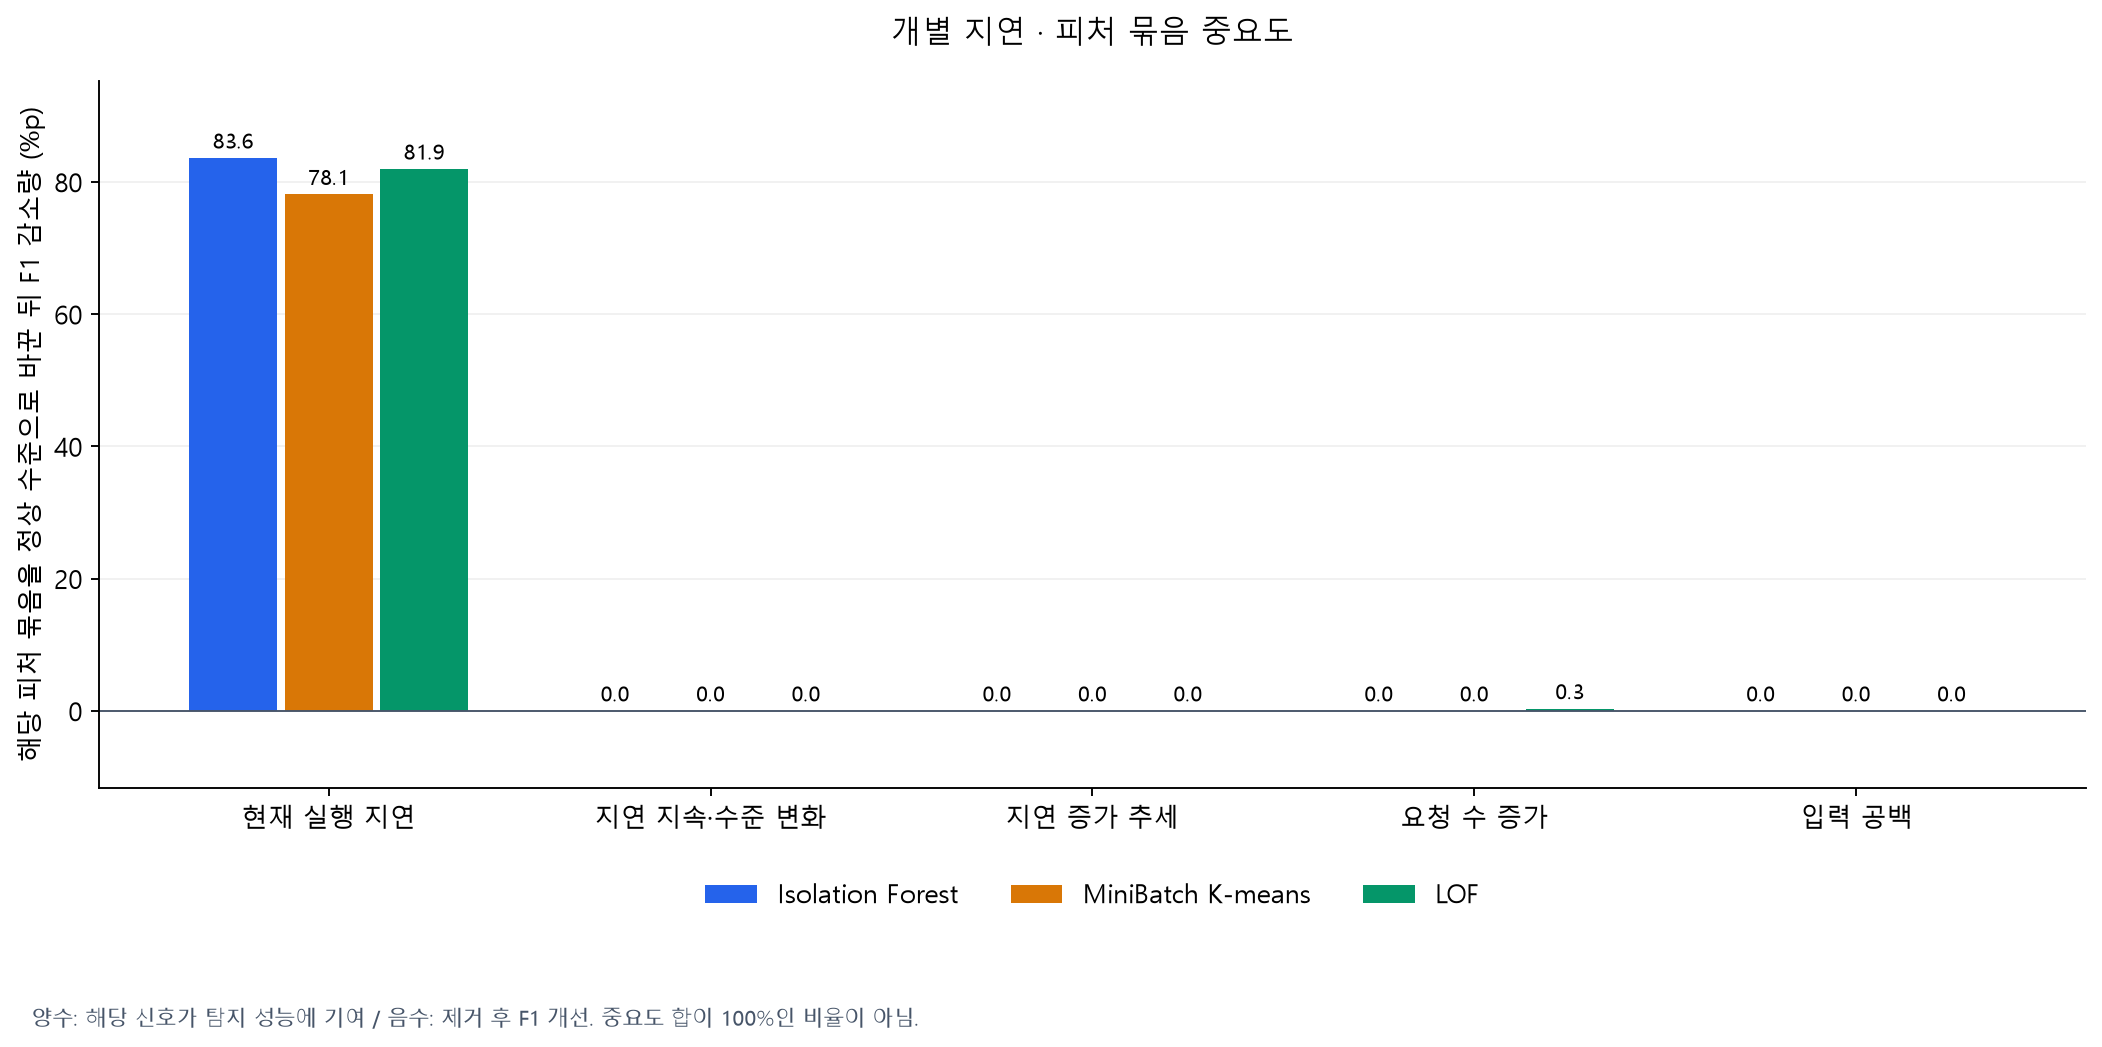

In [6]:
display(Image(filename=str(OUT/'individual_delay_importance.png'))) 

### 집단 지연

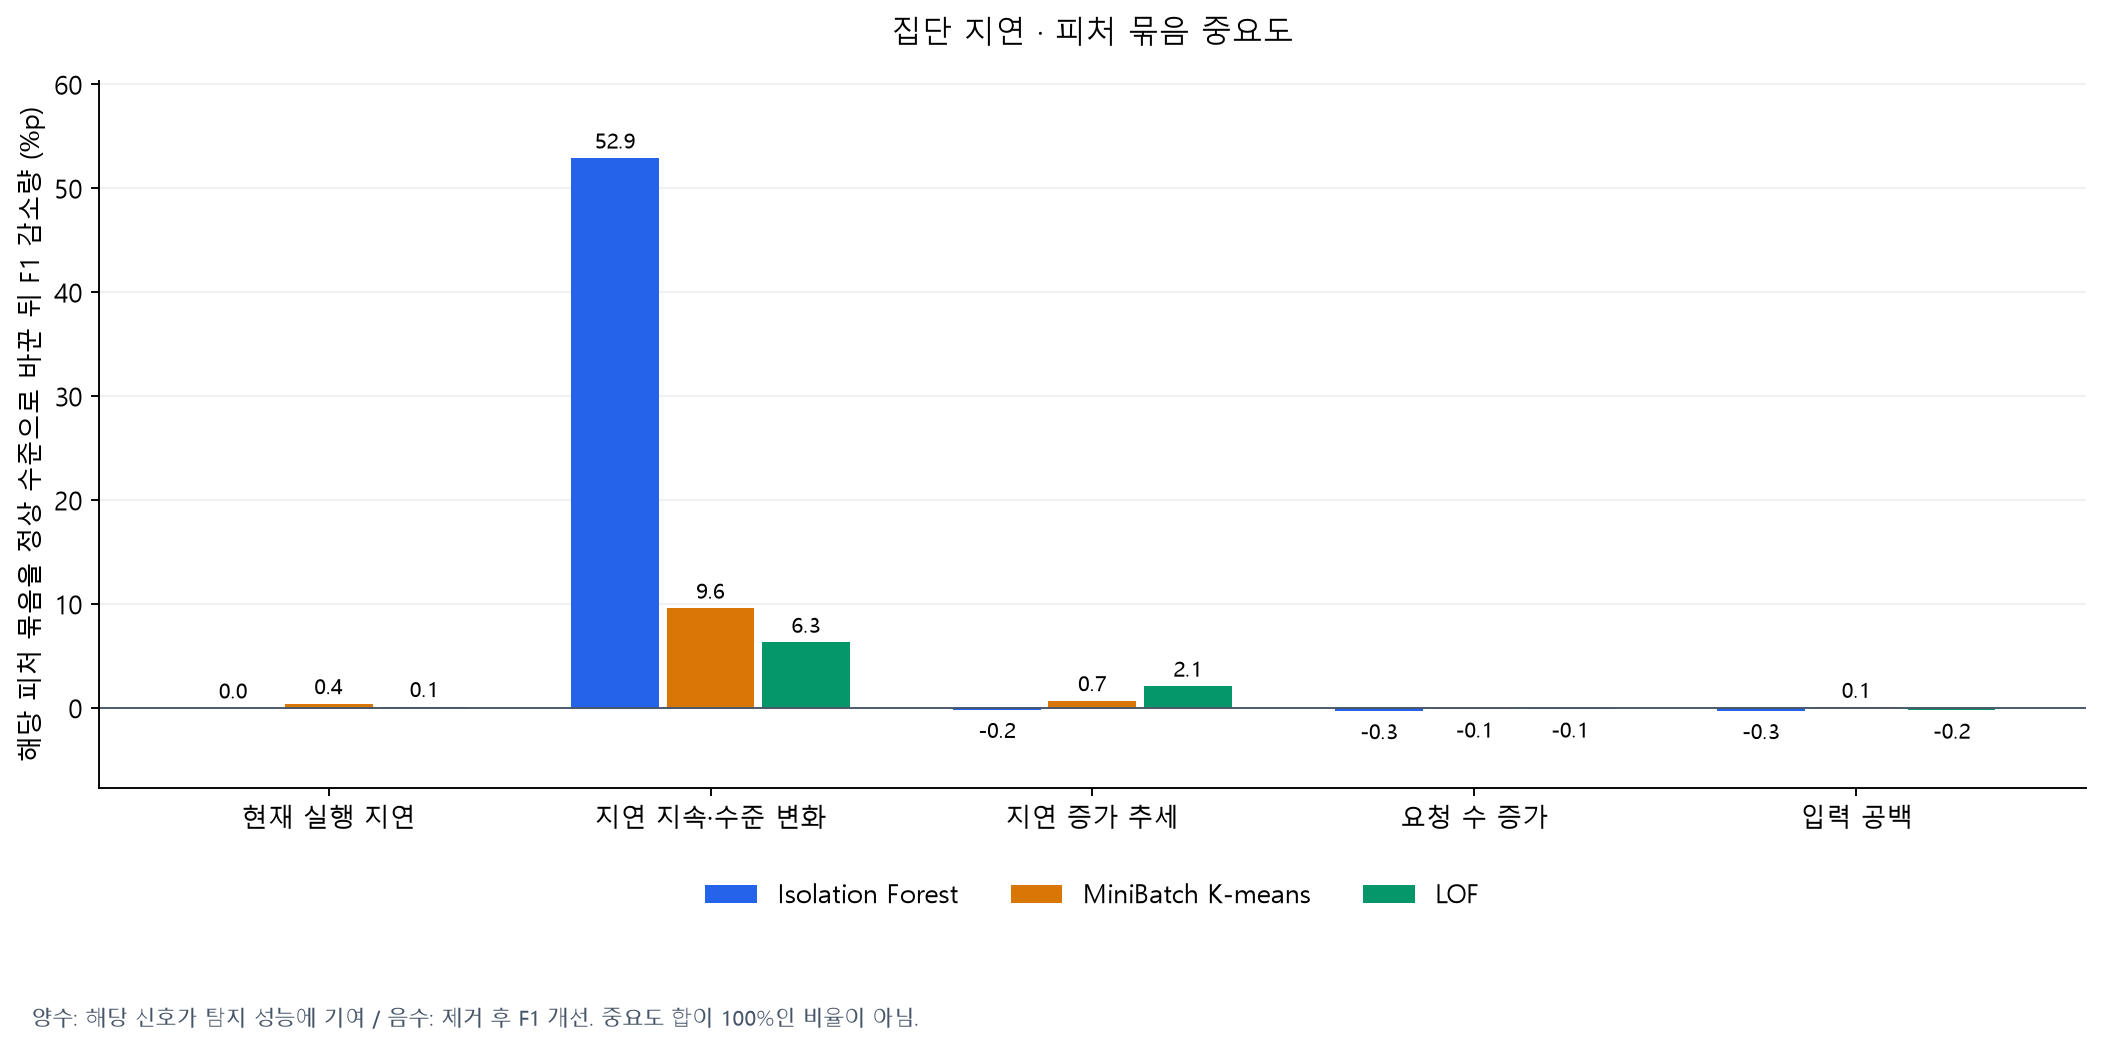

In [7]:
display(Image(filename=str(OUT/'group_delay_importance.png'))) 

### 시간대 폭주

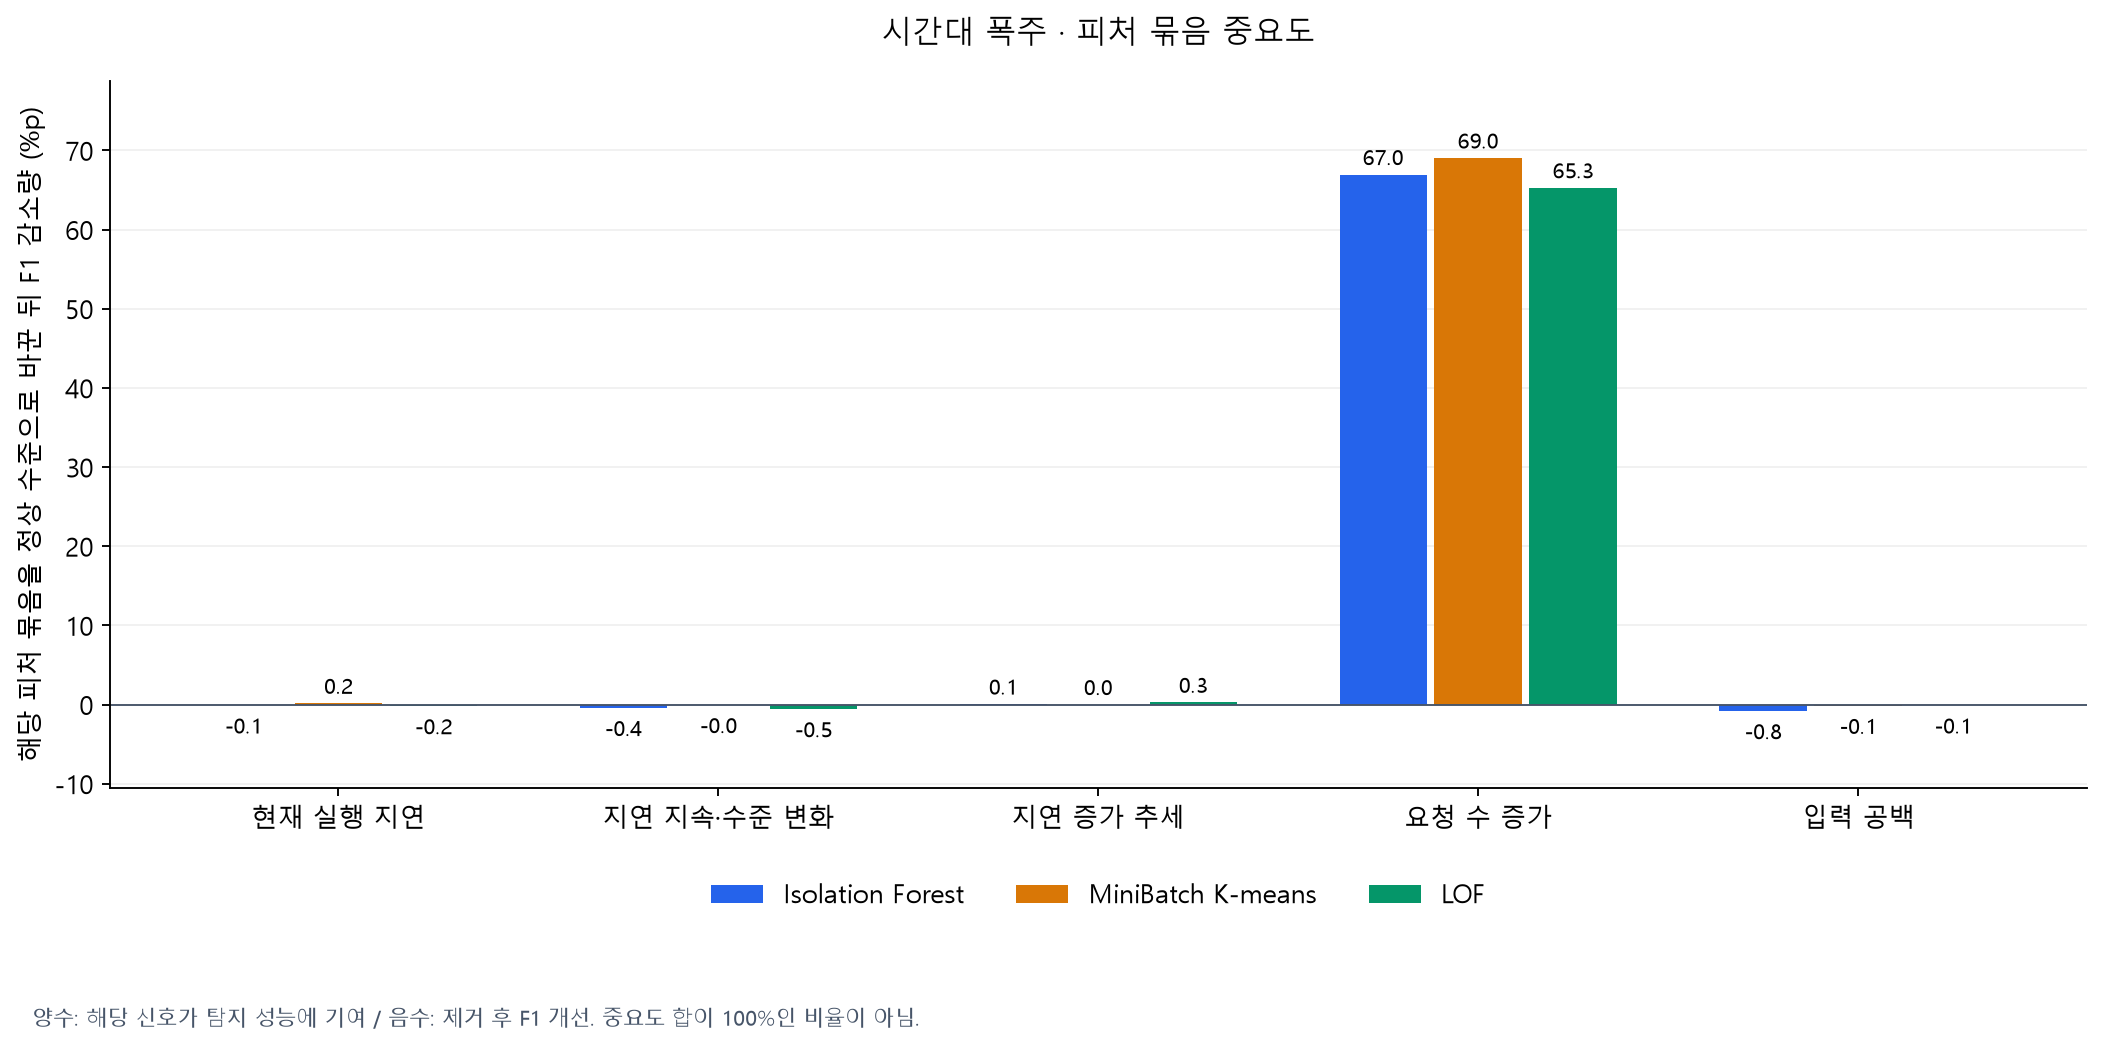

In [8]:
display(Image(filename=str(OUT/'time_burst_importance.png'))) 

### 입력 중단

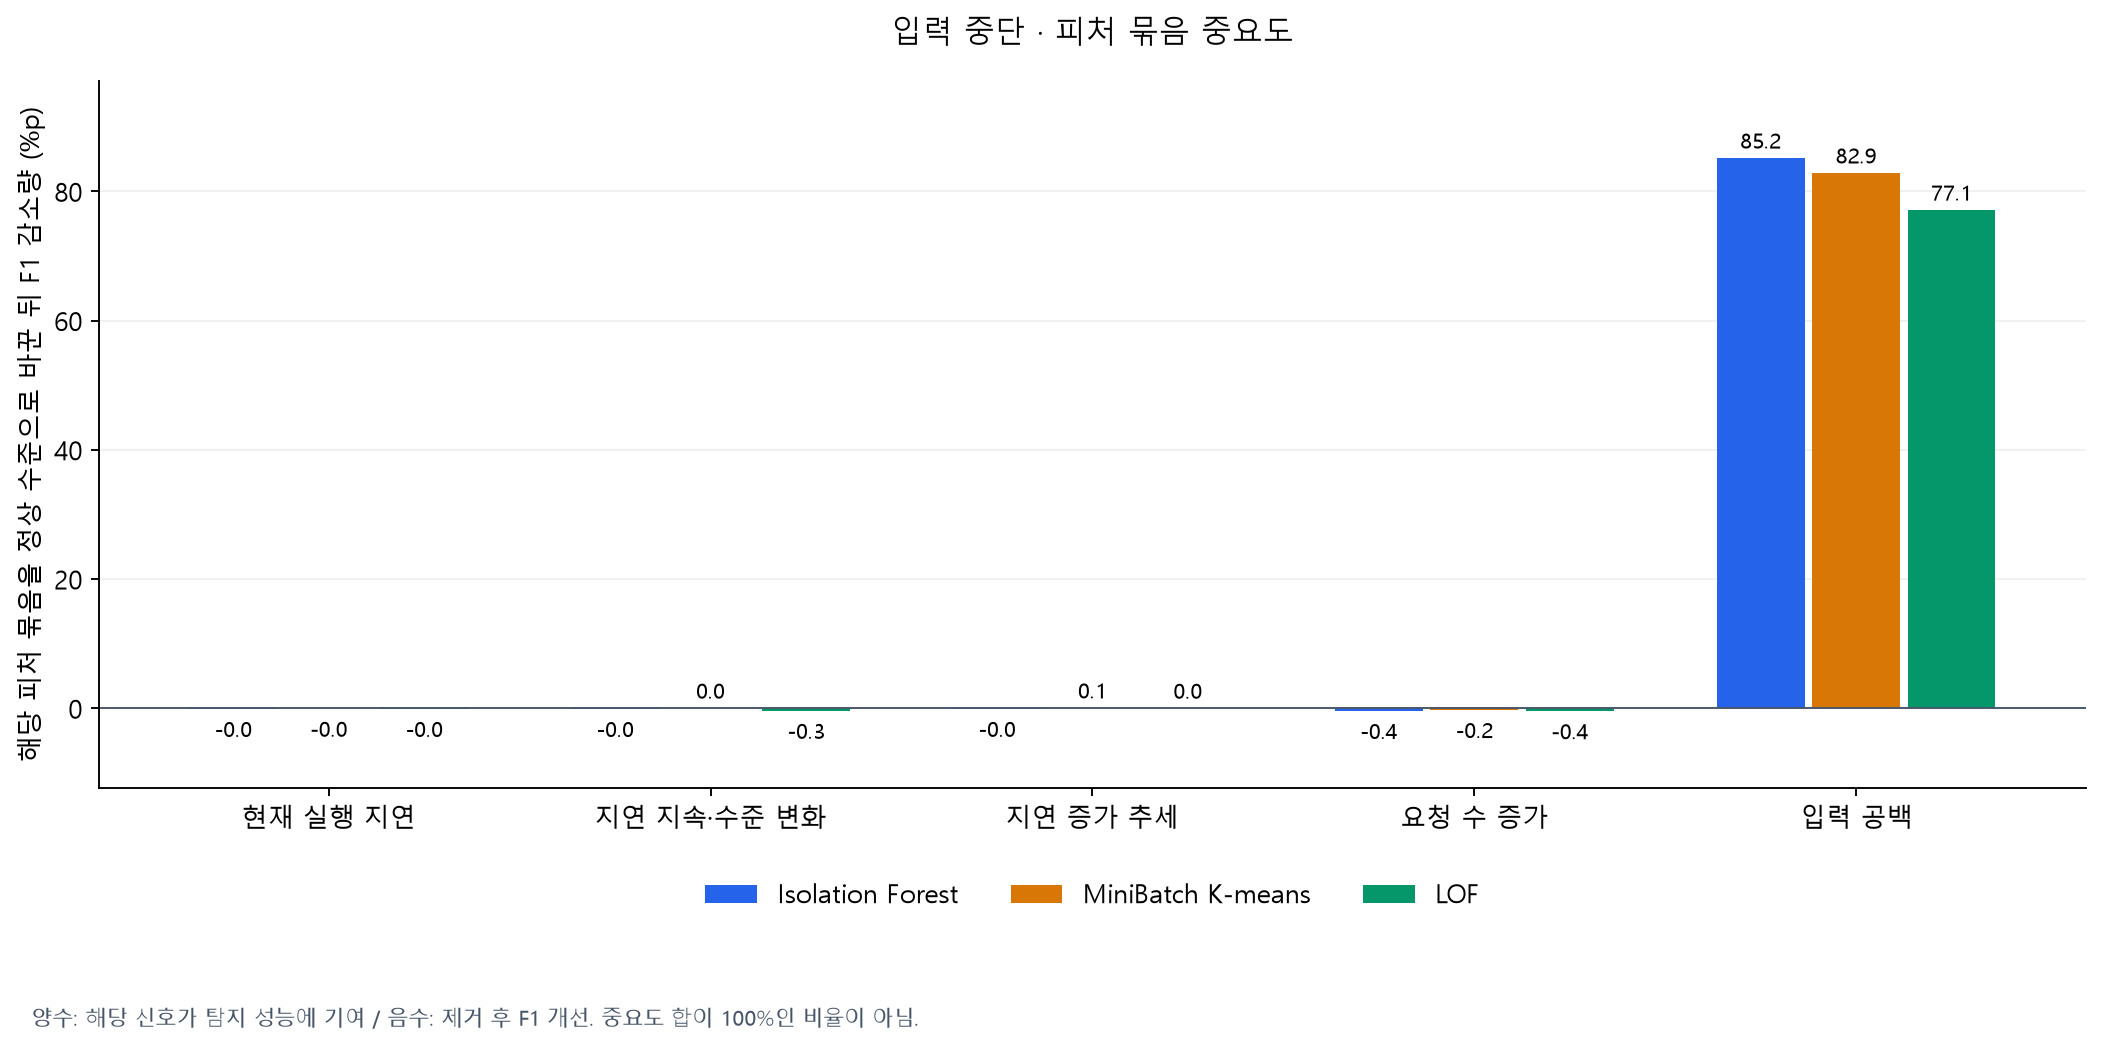

In [9]:
display(Image(filename=str(OUT/'input_stop_importance.png'))) 

### 점진적 악화

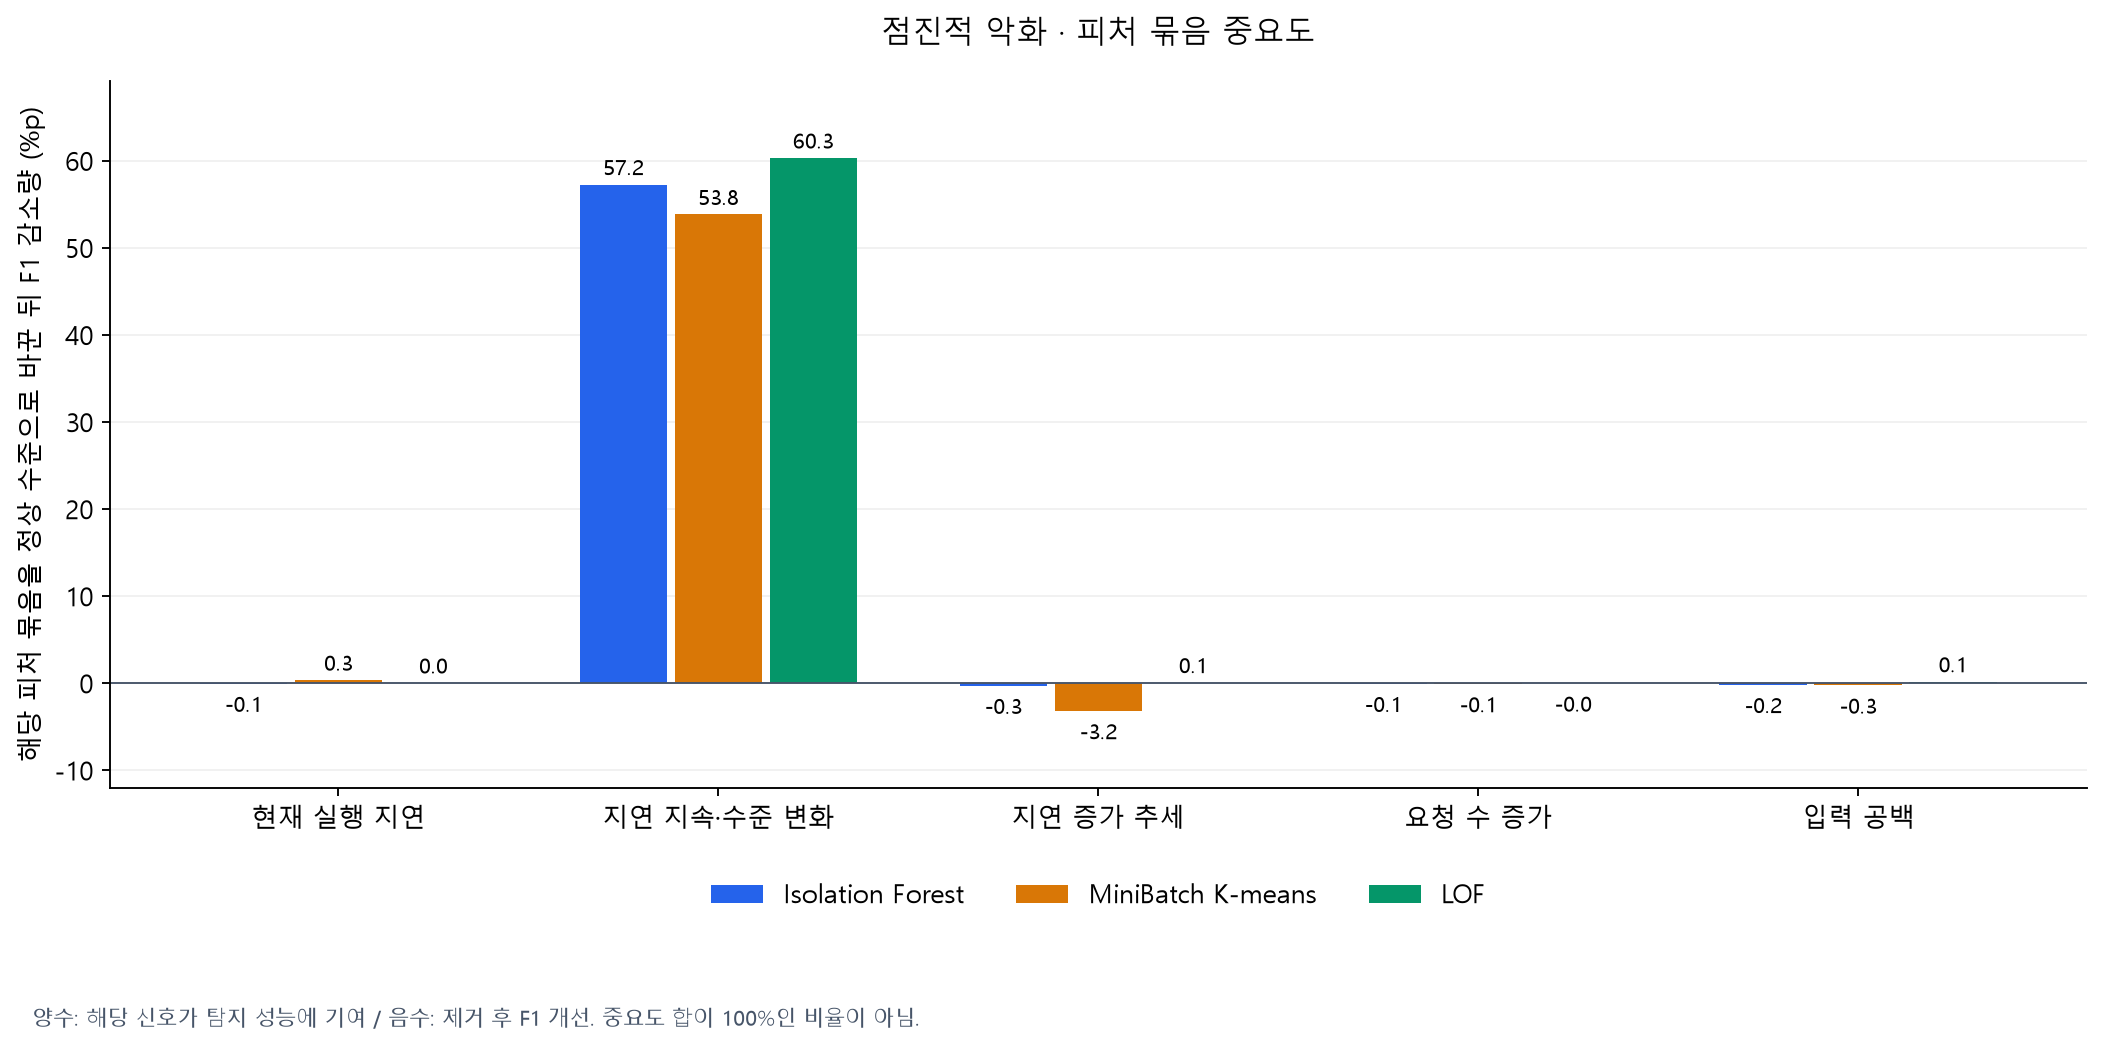

In [10]:
display(Image(filename=str(OUT/'gradual_degradation_importance.png'))) 

## 4. 평가 범위와 해석 주의

- 시나리오별 200개 전체 이상 사례와 짝 정상 200개를 포함한 기존 개발 진단 표본이다. 5,000쌍 전수 평가 성능표와 구분한다.
- 원본 로그, 정답, 모델, 경보선, 기준 통계를 변경하지 않았다. 원래 점수는 릴리스의 동일 판정 점수와 대조했다.
- 막대는 정상 수준 치환에 따른 **F1 감소량(%p)**이다. 모델 고유의 impurity importance나 SHAP 값이 아니다.
- 95% 구간은 정상·이상 쌍을 유지한 사례 단위 bootstrap 400회 결과다. 학습 불확실성이나 실제 운영 성능을 보장하지 않는다.
- 정상 수준 치환으로 피처 조합이 실제 로그와 달라질 수 있고, 관측 신호에 따른 경보 기준 선택도 바뀔 수 있다. 따라서 인과적 장애 원인 또는 순수 알고리즘의 기여로 해석하지 않는다.
- 개발 벤치마크를 반복 사용한 결과다. 이 그림을 보고 피처를 삭제·재학습하려면 별도 미사용 데이터에서 확인해야 한다.
- 입력 중단은 로그가 없는 분도 포함한 타이머 감시가 필요하다. 완료 로그 한 건에 대한 즉시 판정과 별개의 문제다.